# SOEN 400 – Customer Segmentation for Detailed Business Analysis
## Online Retail Dataset – Exploratory Data Analysis (EDA)



## Step 0 – Imports and Setup

In [4]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

DATA_PATH = r'Online Retail.csv'

print('Libraries loaded successfully.')
print(f'Dataset path: {DATA_PATH}')

Libraries loaded successfully.
Dataset path: Online Retail.csv


## Step 1 – Load and Initial Inspection

Purpose: load the raw transaction data and understand its size, columns, data types, missing values, unique values, sample records, and basic numerical statistics.

In [5]:
def read_csv_robust(path):
    for enc in ('utf-8', 'utf-8-sig', 'latin-1', 'cp1252'):
        try:
            df = pd.read_csv(path, encoding=enc)
            print(f"Loaded with encoding='{enc}'")
            return df
        except UnicodeDecodeError:
            continue
    raise RuntimeError(f'Could not read {path} with any common encoding.')

raw = read_csv_robust(DATA_PATH)

print(f'\nDataset shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns')
print(f"Memory usage: {raw.memory_usage(deep=True).sum() / 1e6:.2f} MB")

print('\nColumn names and data types:')
summary = pd.DataFrame({
    'Feature': raw.columns,
    'DType': raw.dtypes.values,
    'Non-Null Count': raw.notnull().sum().values,
    'Unique Values': [raw[c].nunique() for c in raw.columns]
})
display(summary)

print('First 5 rows:')
display(raw.head())

print('Descriptive statistics:')
display(raw.describe().T)

Loaded with encoding='latin-1'

Dataset shape: 541,909 rows × 8 columns
Memory usage: 71.09 MB

Column names and data types:


,Feature,DType,Non-Null Count,Unique Values
0,InvoiceNo,str,541909,25900
1,StockCode,str,541909,4070
2,Description,str,540455,4223
3,Quantity,int64,541909,722
4,InvoiceDate,str,541909,23260
5,UnitPrice,float64,541909,1630
6,CustomerID,float64,406829,4372
7,Country,str,541909,38


First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,3.39,17850.0,United Kingdom


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,15287.690570,1713.600303,12346.00,13953.00,15152.00,16791.00,18287.0


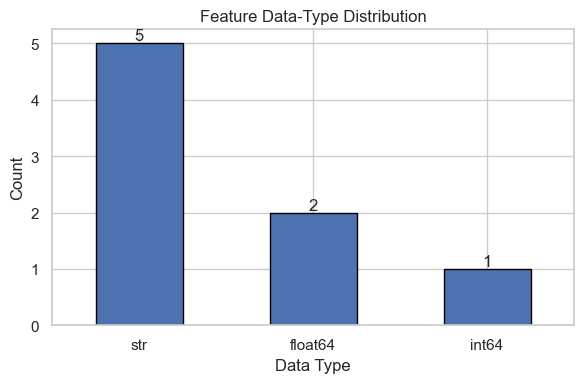

In [6]:
# Figure 1 – Data type distribution
dtype_counts = raw.dtypes.astype(str).value_counts()

fig, ax = plt.subplots(figsize=(6, 4))
dtype_counts.plot(kind='bar', ax=ax, edgecolor='black')
ax.set_title('Feature Data-Type Distribution')
ax.set_xlabel('Data Type')
ax.set_ylabel('Count')
ax.bar_label(ax.containers[0])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 2 – Missing Value Analysis

In [7]:
missing_count = raw.isnull().sum()
missing_pct = (missing_count / len(raw) * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': missing_pct
})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(
    'Missing Count', ascending=False
)

if missing_df.empty:
    print('No missing values were found.')
else:
    print(f'Columns with missing values: {len(missing_df)}')
    display(missing_df)

    rows_affected = int(raw.isnull().any(axis=1).sum())
    print(f'Total missing cells: {int(missing_count.sum()):,}')
    print(f'Rows with at least one missing value: {rows_affected:,} ({rows_affected/len(raw)*100:.2f}%)')

Columns with missing values: 2


,Missing Count,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27


Total missing cells: 136,534
Rows with at least one missing value: 135,080 (24.93%)


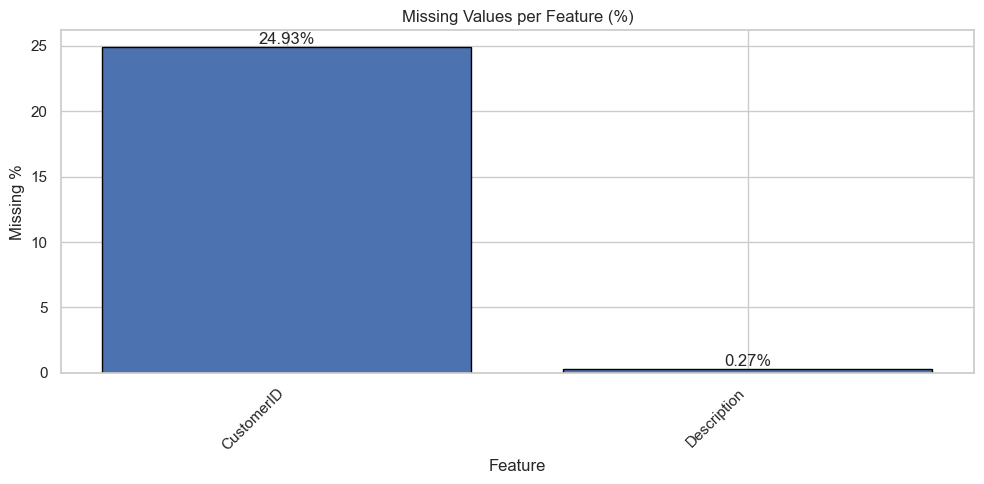

In [8]:
# Figure 2 – Missing values
if not missing_df.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(missing_df.index, missing_df['Missing Percentage'], edgecolor='black')
    ax.set_title('Missing Values per Feature (%)')
    ax.set_ylabel('Missing %')
    ax.set_xlabel('Feature')
    ax.bar_label(bars, fmt='%.2f%%')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

## Step 3 – Duplicate Row Analysis

In [9]:
duplicate_count = int(raw.duplicated().sum())
duplicate_pct = duplicate_count / len(raw) * 100

print(f'Exact duplicate rows: {duplicate_count:,} ({duplicate_pct:.2f}%)')

Exact duplicate rows: 5,268 (0.97%)


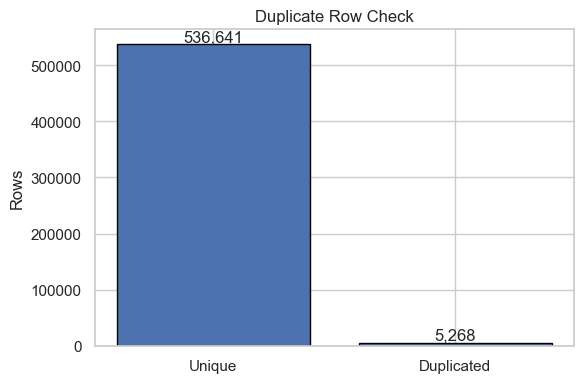

In [10]:
# Figure 3 – Duplicate row check
fig, ax = plt.subplots(figsize=(6, 4))
labels = ['Unique', 'Duplicated']
values = [len(raw) - duplicate_count, duplicate_count]
bars = ax.bar(labels, values, edgecolor='black')
ax.set_title('Duplicate Row Check')
ax.set_ylabel('Rows')
ax.bar_label(bars, labels=[f'{v:,}' for v in values])
plt.tight_layout()
plt.show()

## Step 4 – Transaction-Level Data-Quality Checks

This step checks cancellation records, unusual quantities, unusual prices, missing customer IDs, and the date range.

In [11]:
def parse_dates(series):
    parsed = pd.to_datetime(series, format='%Y-%m-%d %H:%M:%S', errors='coerce')
    if parsed.notna().sum() == 0:
        parsed = pd.to_datetime(series, errors='coerce', dayfirst=False)
    return parsed

quality_flags = {}

if 'InvoiceNo' in raw.columns:
    invoice = raw['InvoiceNo'].astype(str)
    quality_flags['Cancelled invoices (start C)'] = int(invoice.str.startswith('C').sum())

if 'Quantity' in raw.columns:
    quality_flags['Quantity ≤ 0'] = int((raw['Quantity'] <= 0).sum())
    quality_flags['Quantity < 0 (returns)'] = int((raw['Quantity'] < 0).sum())

if 'UnitPrice' in raw.columns:
    quality_flags['UnitPrice ≤ 0'] = int((raw['UnitPrice'] <= 0).sum())
    quality_flags['UnitPrice == 0'] = int((raw['UnitPrice'] == 0).sum())
    quality_flags['UnitPrice < 0'] = int((raw['UnitPrice'] < 0).sum())

if 'CustomerID' in raw.columns:
    quality_flags['Missing CustomerID'] = int(raw['CustomerID'].isnull().sum())

dates = parse_dates(raw['InvoiceDate'])
print(f'Unparseable dates: {int(dates.isnull().sum()):,}')
print(f'Date range: {dates.min()} → {dates.max()}')

quality_df = pd.DataFrame({
    'Issue': quality_flags.keys(),
    'Count': quality_flags.values()
})
quality_df['Percentage'] = (quality_df['Count'] / len(raw) * 100).round(2)
display(quality_df)

Unparseable dates: 308,950
Date range: 2010-01-12 08:26:00 → 2011-12-10 17:19:00


,Issue,Count,Percentage
0,Cancelled invoices (start C),9288,1.71
1,Quantity ≤ 0,10624,1.96
2,Quantity < 0 (returns),10624,1.96
3,UnitPrice ≤ 0,2517,0.46
4,UnitPrice == 0,2515,0.46
5,UnitPrice < 0,2,0.00
6,Missing CustomerID,135080,24.93


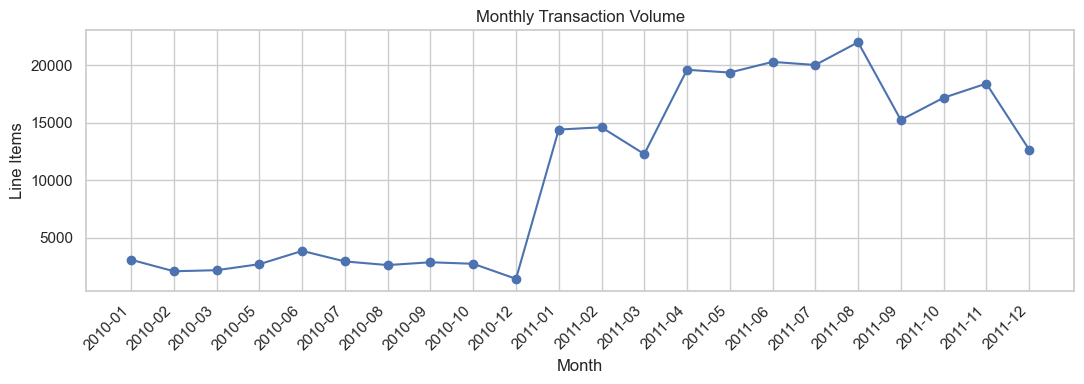

In [12]:
# Figure 4 – Monthly transaction volume
monthly = dates.dropna().dt.to_period('M').value_counts().sort_index()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index.astype(str), monthly.values, marker='o')
ax.set_title('Monthly Transaction Volume')
ax.set_ylabel('Line Items')
ax.set_xlabel('Month')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

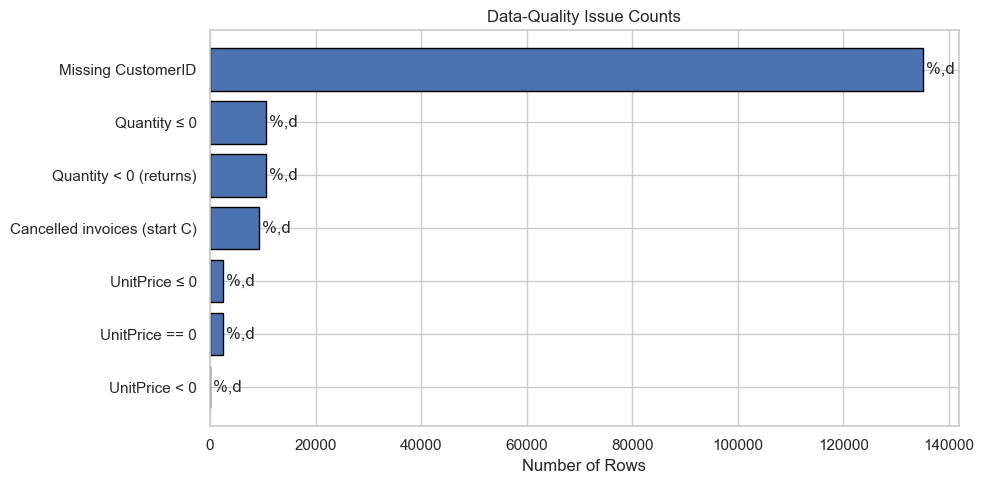

In [13]:
# Figure 5 – Data-quality issue counts
fig, ax = plt.subplots(figsize=(10, 5))
ordered = quality_df.sort_values('Count')
bars = ax.barh(ordered['Issue'], ordered['Count'], edgecolor='black')
ax.set_title('Data-Quality Issue Counts')
ax.set_xlabel('Number of Rows')
ax.bar_label(bars, fmt='%,d', padding=2)
plt.tight_layout()
plt.show()

## Step 5 – Build Customer-Level RFM Table

The raw data is transaction-level. For customer segmentation, it is transformed into one row per customer using:

- **Recency:** days since the customer's most recent purchase
- **Frequency:** number of unique invoices
- **Monetary:** total customer spending

In [14]:
clean = raw.copy()

clean = clean.dropna(subset=['CustomerID'])
clean = clean[~clean['InvoiceNo'].astype(str).str.startswith('C')]
clean = clean[clean['Quantity'] > 0]
clean = clean[clean['UnitPrice'] > 0]
clean = clean.drop_duplicates()

clean['InvoiceDate'] = parse_dates(clean['InvoiceDate'])
clean = clean.dropna(subset=['InvoiceDate'])
clean['TotalPrice'] = clean['Quantity'] * clean['UnitPrice']
clean['CustomerID'] = clean['CustomerID'].astype(float).astype(int)

print(f'Rows kept after cleaning: {len(clean):,}')
print(f'Rows retained: {len(clean)/len(raw)*100:.2f}%')

snapshot_date = clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f'Snapshot date: {snapshot_date.date()}')

rfm = clean.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda s: (snapshot_date - s.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum')
).reset_index()

print(f'\nRFM table: {rfm.shape[0]:,} customers × {rfm.shape[1]} columns')
display(rfm.head())

print('RFM descriptive statistics:')
display(rfm[['Recency', 'Frequency', 'Monetary']].describe().T)

Rows kept after cleaning: 166,363
Rows retained: 30.70%
Snapshot date: 2011-12-11

RFM table: 2,997 customers × 4 columns


,CustomerID,Recency,Frequency,Monetary
0,12347,96,5,2540.29
1,12348,221,1,367.00
2,12350,312,1,334.40
3,12352,275,3,1296.38
4,12355,97,1,459.40


RFM descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Recency,2997.0,155.387387,140.138120,1.0,40.00,125.00,219.00,698.0
Frequency,2997.0,2.656323,4.008919,1.0,1.00,2.00,3.00,106.0
Monetary,2997.0,1289.777471,5273.011876,5.9,244.41,466.29,1064.28,168469.6


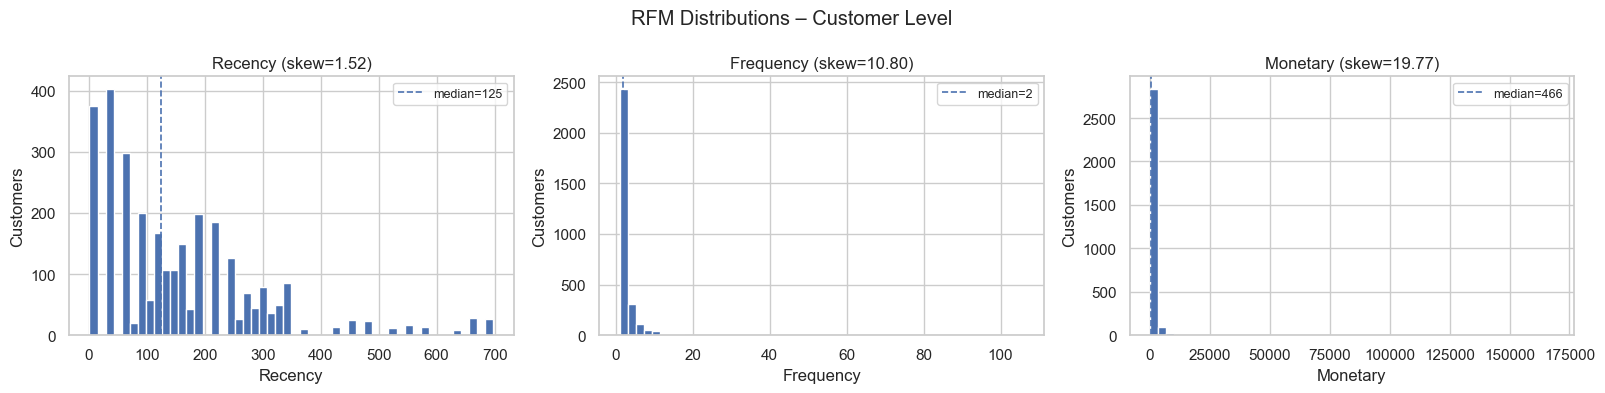

In [15]:
# Figure 6 – RFM distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    ax.hist(rfm[col], bins=50, edgecolor='white')
    ax.set_title(f'{col} (skew={rfm[col].skew():.2f})')
    ax.set_xlabel(col)
    ax.set_ylabel('Customers')
    median = rfm[col].median()
    ax.axvline(median, linestyle='--', linewidth=1.2, label=f'median={median:,.0f}')
    ax.legend(fontsize=9)

plt.suptitle('RFM Distributions – Customer Level')
plt.tight_layout()
plt.show()

## Step 6 – Outlier Detection on RFM

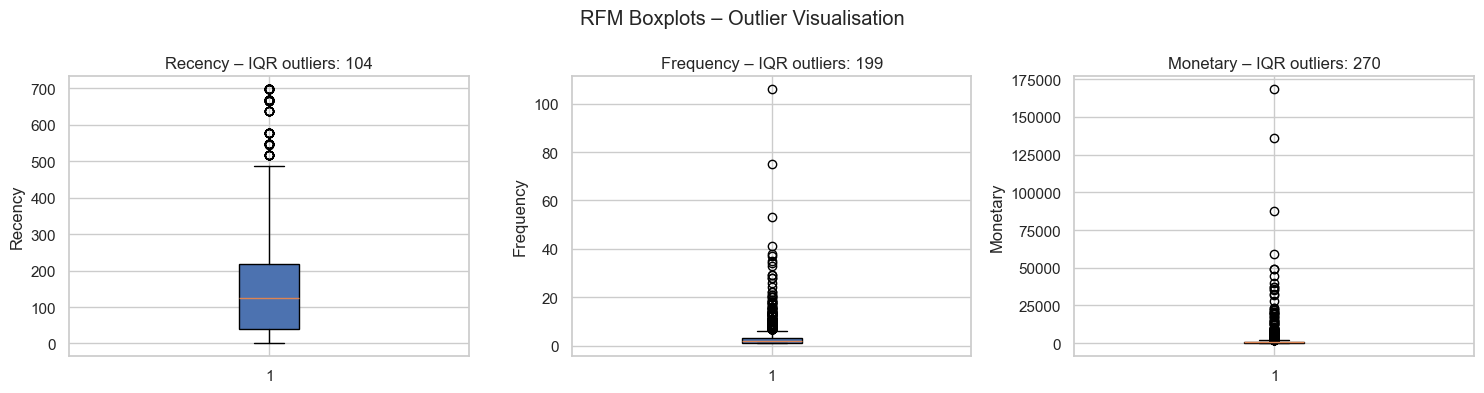

,Feature,Lower (IQR),Upper (IQR),Outliers IQR,Outliers Z>3,% Outliers
0,Recency,-228.5,487.50,104,76,3.47
1,Frequency,-2.0,6.00,199,40,6.64
2,Monetary,-985.4,2294.08,270,27,9.01


In [16]:
features = ['Recency', 'Frequency', 'Monetary']
outlier_summary = []

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, features):
    q1 = rfm[col].quantile(0.25)
    q3 = rfm[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_iqr = int(((rfm[col] < lower) | (rfm[col] > upper)).sum())
    z = np.abs(stats.zscore(rfm[col]))
    n_z = int((z > 3).sum())

    ax.boxplot(rfm[col], patch_artist=True)
    ax.set_title(f'{col} – IQR outliers: {n_iqr:,}')
    ax.set_ylabel(col)

    outlier_summary.append({
        'Feature': col,
        'Lower (IQR)': round(lower, 2),
        'Upper (IQR)': round(upper, 2),
        'Outliers IQR': n_iqr,
        'Outliers Z>3': n_z,
        '% Outliers': round(n_iqr / len(rfm) * 100, 2)
    })

plt.suptitle('RFM Boxplots – Outlier Visualisation')
plt.tight_layout()
plt.show()

display(pd.DataFrame(outlier_summary))

## Step 7 – Correlation Analysis

Pearson correlations:


,Recency,Frequency,Monetary
Recency,1.000,-0.255,-0.119
Frequency,-0.255,1.000,0.451
Monetary,-0.119,0.451,1.000


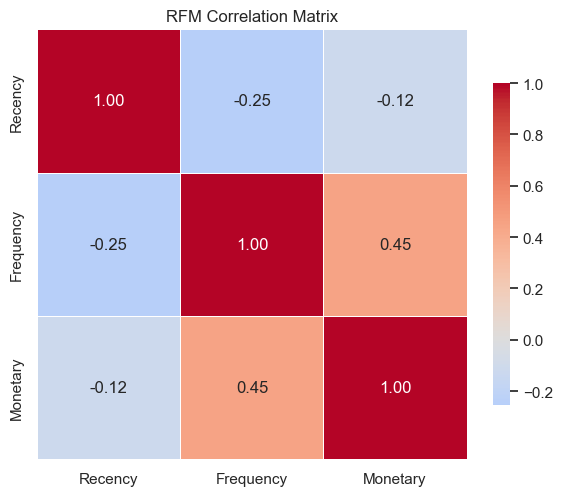

In [17]:
rfm_cols = ['Recency', 'Frequency', 'Monetary']
corr = rfm[rfm_cols].corr()

print('Pearson correlations:')
display(corr.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, square=True, cbar_kws={'shrink': 0.75}, ax=ax)
ax.set_title('RFM Correlation Matrix')
plt.tight_layout()
plt.show()

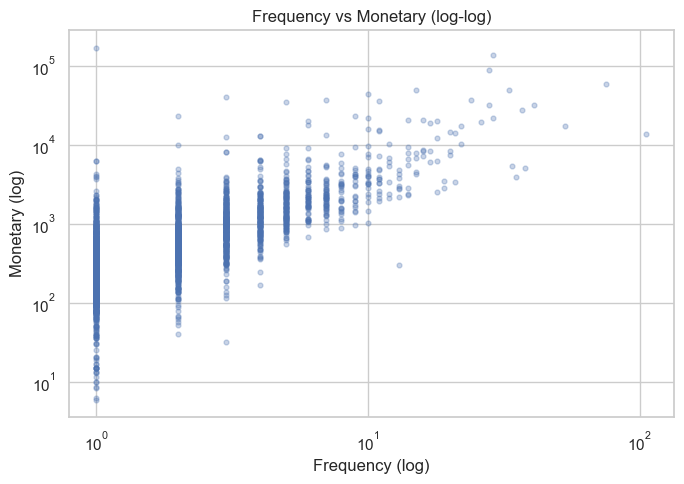

In [18]:
# Figure – Frequency vs Monetary on log scales
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(rfm['Frequency'], rfm['Monetary'], alpha=0.3, s=12)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Frequency (log)')
ax.set_ylabel('Monetary (log)')
ax.set_title('Frequency vs Monetary (log-log)')
plt.tight_layout()
plt.show()

## Step 8 – Pairwise Relationships

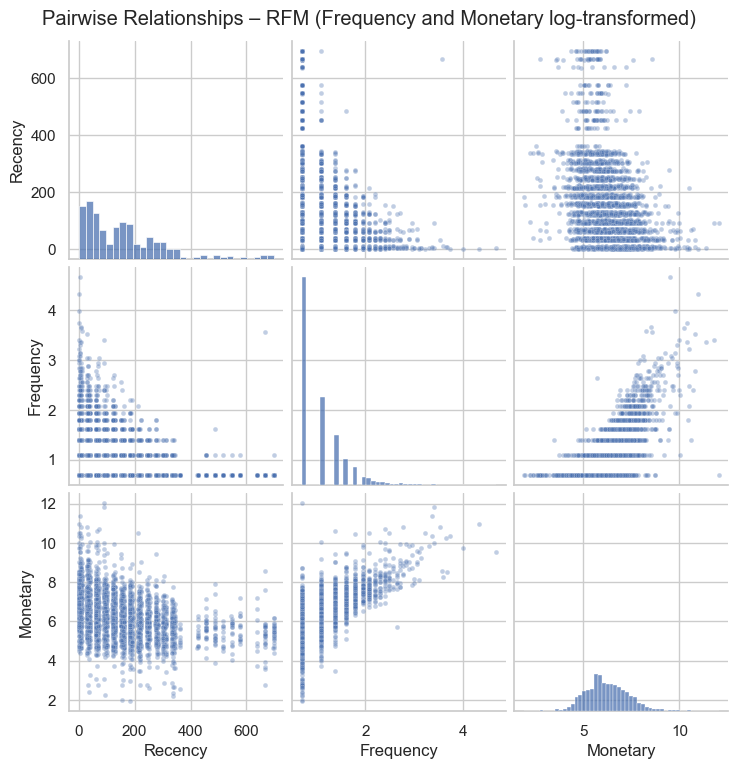

In [19]:
pairwise = rfm[rfm_cols].copy()
pairwise['Frequency'] = np.log1p(pairwise['Frequency'])
pairwise['Monetary'] = np.log1p(pairwise['Monetary'])

g = sns.pairplot(
    pairwise,
    diag_kind='hist',
    plot_kws={'alpha': 0.35, 's': 12}
)
g.fig.suptitle('Pairwise Relationships – RFM (Frequency and Monetary log-transformed)',
               y=1.02)
plt.show()

## Step 9 – Scaling Preview

This step compares the numerical ranges before scaling. This matters because K-Means uses distance calculations and variables with much larger ranges can dominate those distances.

,min,max,range,std
Monetary,5.9,168469.6,168463.7,5273.011876
Recency,1.0,698.0,697.0,140.138120
Frequency,1.0,106.0,105.0,4.008919


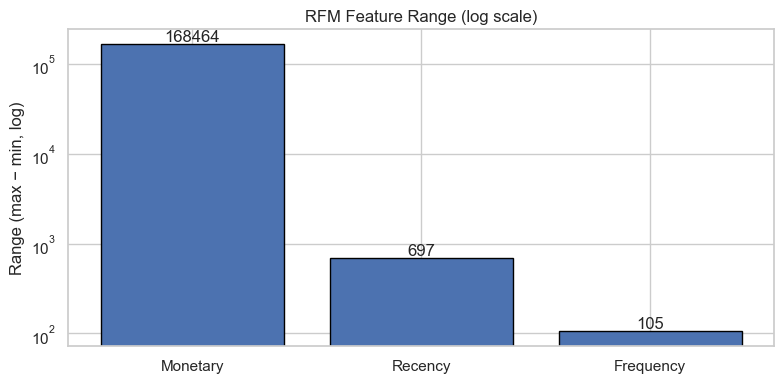

In [20]:
ranges = pd.DataFrame({
    'min': rfm[rfm_cols].min(),
    'max': rfm[rfm_cols].max(),
    'range': rfm[rfm_cols].max() - rfm[rfm_cols].min(),
    'std': rfm[rfm_cols].std()
}).sort_values('range', ascending=False)

display(ranges)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(ranges.index, ranges['range'], edgecolor='black')
ax.set_yscale('log')
ax.set_title('RFM Feature Range (log scale)')
ax.set_ylabel('Range (max − min, log)')
ax.bar_label(bars, fmt='%.0f')
plt.tight_layout()
plt.show()

## Step 10 – Consolidated Project Findings

The following outputs are calculated from the data rather than being fixed statements, so the notebook documents what is actually observed.

In [21]:
missing_customer_id = int(raw['CustomerID'].isnull().sum()) if 'CustomerID' in raw.columns else None
cancelled = int(raw['InvoiceNo'].astype(str).str.startswith('C').sum()) if 'InvoiceNo' in raw.columns else None
returns = int((raw['Quantity'] < 0).sum()) if 'Quantity' in raw.columns else None

print('DATASET AT A GLANCE')
print(f'Raw transactions        : {len(raw):,}')
print(f'Raw columns             : {raw.shape[1]}')
print(f'Unique customers (RFM)  : {len(rfm):,}')
print(f'Missing CustomerID rows : {missing_customer_id:,}')
print(f'Cancelled invoices      : {cancelled:,}')
print(f'Return lines (Qty < 0)  : {returns:,}')

print('\nOBSERVED DATA-QUALITY ISSUES')
display(quality_df)

print('\nPRELIMINARY RFM FINDINGS')
print(f"Frequency skewness : {rfm['Frequency'].skew():.2f}")
print(f"Monetary skewness  : {rfm['Monetary'].skew():.2f}")
print(f"Recency skewness   : {rfm['Recency'].skew():.2f}")
print(f"Frequency–Monetary correlation: {corr.loc['Frequency', 'Monetary']:.3f}")
print(f"Recency–Monetary correlation: {corr.loc['Recency', 'Monetary']:.3f}")
print(f"RFM customers available for clustering: {len(rfm):,}")

DATASET AT A GLANCE
Raw transactions        : 541,909
Raw columns             : 8
Unique customers (RFM)  : 2,997
Missing CustomerID rows : 135,080
Cancelled invoices      : 9,288
Return lines (Qty < 0)  : 10,624

OBSERVED DATA-QUALITY ISSUES


,Issue,Count,Percentage
0,Cancelled invoices (start C),9288,1.71
1,Quantity ≤ 0,10624,1.96
2,Quantity < 0 (returns),10624,1.96
3,UnitPrice ≤ 0,2517,0.46
4,UnitPrice == 0,2515,0.46
5,UnitPrice < 0,2,0.00
6,Missing CustomerID,135080,24.93



PRELIMINARY RFM FINDINGS
Frequency skewness : 10.80
Monetary skewness  : 19.77
Recency skewness   : 1.52
Frequency–Monetary correlation: 0.451
Recency–Monetary correlation: -0.119
RFM customers available for clustering: 2,997


## Optional – Save the Customer-Level RFM Table

The figures are **not** saved automatically. They remain visible directly in the notebook. This optional cell only saves the RFM table needed for the next clustering stage.

In [22]:
rfm.to_csv(r'C:\Users\C_Tr\Desktop\G3\data\rfm_customers.csv', index=False)
print('Saved customer-level RFM table to: C:\\Users\\C_Tr\\Desktop\\G3\\data\\rfm_customers.csv')

OSError: Cannot save file into a non-existent directory: 'C:\Users\C_Tr\Desktop\G3\data'